In [ ]:
!pip install -q torch torchvision matplotlib pillow torchmetrics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 49.4 MB/s eta 0:00:00


In [ ]:
import os
import random
import zipfile
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from torch.utils.data import DataLoader

from google.colab import files

from torchmetrics.image import PeakSignalNoiseRatio
from torchmetrics.image import StructuralSimilarityIndexMeasure


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)


Device: cuda


## Konfigurasyon



In [ ]:
IMAGE_SIZE = 64
TAESD_INPUT_SIZE = 512

NUM_ASCII_CLASSES = 256

SAMPLES_PER_CLASS = 4
SAMPLES_PER_EPOCH = (
    NUM_ASCII_CLASSES * SAMPLES_PER_CLASS
)

EPOCHS = 75
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

DELTA_SCALE = 0.10

CLASS_WEIGHT = 1.0
IMAGE_WEIGHT = 0.1

## Veri Yukleme

In [ ]:
uploaded = files.upload()

zip_name = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall()

print(os.listdir())


Saving 100_images.zip to 100_images.zip
['.config', '100_images.zip', '__MACOSX', '100_images', 'sample_data']


In [ ]:
TRAIN_DIR = "100_images/train"
TEST_DIR = "100_images/test"

to_tensor_resize = transforms.Compose([
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        antialias=True
    ),
    transforms.ToTensor()
])


def load_images(folder):

    image_files = []

    for fname in sorted(os.listdir(folder)):

        if fname.lower().endswith(
            (".jpg", ".jpeg", ".png", ".webp")
        ):
            image_files.append(
                os.path.join(folder, fname)
            )

    images = []

    for path in image_files:

        image = Image.open(path).convert("RGB")
        image = to_tensor_resize(image)

        images.append(image)

    if len(images) == 0:
        raise RuntimeError(
            f"{folder} klasorunde goruntu bulunamadi."
        )

    images = torch.stack(images)

    return images, image_files


x_train, train_files = load_images(TRAIN_DIR)
x_test, test_files = load_images(TEST_DIR)

print("Train image count:", len(x_train))
print("Train tensor shape:", x_train.shape)

print("Test image count:", len(x_test))
print("Test tensor shape:", x_test.shape)


Train image count: 100
Train tensor shape: torch.Size([100, 3, 64, 64])
Test image count: 12
Test tensor shape: torch.Size([12, 3, 64, 64])


## TAESD

In [ ]:
TAESD_BASE_URL = "https://raw.githubusercontent.com/madebyollin/taesd/main"

TAESD_FILES = [
    "taesd.py",
    "taesd_encoder.pth",
    "taesd_decoder.pth"
]

for fname in TAESD_FILES:

    if not os.path.exists(fname):

        print("Downloading:", fname)

        urllib.request.urlretrieve(f"{TAESD_BASE_URL}/{fname}", fname)

from taesd import TAESD

print("TAESD dosyalari hazir.")


Downloading: taesd.py
Downloading: taesd_encoder.pth
Downloading: taesd_decoder.pth
TAESD dosyalari hazir.


In [ ]:
taesd = TAESD(
    encoder_path="taesd_encoder.pth",
    decoder_path="taesd_decoder.pth"
).to(DEVICE)

taesd.eval()

print("TAESD yuklendi.")


TAESD yuklendi.


In [ ]:


for parameter in taesd.encoder.parameters():
    parameter.requires_grad_(False)

for parameter in taesd.decoder.parameters():
    parameter.requires_grad_(False)

taesd.eval()

print(
    "Encoder trainable:",
    any(p.requires_grad for p in taesd.encoder.parameters())
)

print(
    "Decoder trainable:",
    any(p.requires_grad for p in taesd.decoder.parameters())
)


Encoder trainable: False
Decoder trainable: False


In [ ]:

upsample_512 = transforms.Resize(
    (TAESD_INPUT_SIZE, TAESD_INPUT_SIZE),
    antialias=True
)


downsample_64 = transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE),
    antialias=True
)

print(
    f"Pipeline resize: "
    f"{IMAGE_SIZE} -> {TAESD_INPUT_SIZE} -> {IMAGE_SIZE}"
)

Pipeline resize: 64 -> 512 -> 64


In [ ]:
with torch.no_grad():

    sample_512 = upsample_512(
        x_train[:1].to(DEVICE)
    )

    sample_latent = taesd.encoder(
        sample_512
    )

LATENT_CHANNELS = sample_latent.shape[1]
LATENT_SIZE = sample_latent.shape[2]


calculating latent_std, max_delta

In [ ]:
with torch.no_grad():

    latent_samples = []

    for start in range(0, len(x_train), 8):

        batch_64 = x_train[
            start:start + 8
        ].to(DEVICE)

        batch_512 = upsample_512(
            batch_64
        )

        latent_batch = taesd.encoder(
            batch_512
        )

        latent_samples.append(
            latent_batch
        )

    all_latents = torch.cat(
        latent_samples,
        dim=0
    )

LATENT_STD = all_latents.std().item()

MAX_DELTA = DELTA_SCALE * LATENT_STD

print("Latent std:", LATENT_STD)
print("Maximum delta:", MAX_DELTA)


Latent std: 1.004361629486084
Maximum delta: 0.10043616294860841


In [ ]:
def create_epoch_ascii_labels(samples_per_class,device):

    #[0,0,0,0,1,1,1,1,...,255,255,255,255]
    labels = torch.arange(NUM_ASCII_CLASSES,dtype=torch.long,device=device)
    .repeat_interleave(samples_per_class)

    permutation = torch.randperm(labels.size(0),device=device)

    labels = labels[permutation]

    return labels

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os

CHECKPOINT_DIR = (
    "/content/drive/MyDrive/"
    "TAESD_256_Message_Checkpoints"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_latent_steganography_256_classes.pth"
)

LATEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "latest_latent_steganography_256_classes.pth"
)

print("Checkpoint directory:")
print(CHECKPOINT_DIR)

print("\nBest checkpoint:")
print(BEST_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(LATEST_CHECKPOINT_PATH)

Mounted at /content/drive
Checkpoint directory:
/content/drive/MyDrive/TAESD_256_Message_Checkpoints

Best checkpoint:
/content/drive/MyDrive/TAESD_256_Message_Checkpoints/best_latent_steganography_256_classes.pth

Latest checkpoint:
/content/drive/MyDrive/TAESD_256_Message_Checkpoints/latest_latent_steganography_256_classes.pth


##  Modeller



In [ ]:
class LatentEmbedder(nn.Module):

    def __init__(self,num_classes,latent_channels,latent_size,max_delta):

        super().__init__()

        self.latent_channels = latent_channels
        self.latent_size = latent_size
        self.max_delta = max_delta

        # message class -> vector with 128 dim
        self.message_embedding = nn.Embedding(num_embeddings=num_classes,embedding_dim=128)

        # message -> 8x8
        self.message_projection = nn.Sequential(
            nn.Linear(128,256 * 8 * 8),nn.ReLU()
        )

        # 8x8x256 -> 32x64x64
        self.message_upsampler = nn.Sequential(
            nn.ConvTranspose2d(256,128,kernel_size=4,stride=2,padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128,64,kernel_size=4,stride=2,padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64,32,kernel_size=4,stride=2,padding=1),
            nn.ReLU()
        )


        # 36x64x64 -> 4x64x64
        self.delta_network = nn.Sequential(
            nn.Conv2d(latent_channels + 32,64,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.Conv2d(64,32,kernel_size=3,padding=1),
            nn.ReLU(),
            nn.Conv2d(32,latent_channels,kernel_size=3,padding=1)
        )

    def forward(self,latent_clean,message_labels):

        batch_size = latent_clean.size(0)
        # message -> 128D vector
        message_vector = self.message_embedding(message_labels)
        # vector 8x8x256 feature map
        message_map = self.message_projection(message_vector)

        message_map = message_map.view(batch_size,256,8,8)
        # 8x8x256 -> 32x64x64
        message_map = self.message_upsampler(message_map)

        combined_input = torch.cat(
            [latent_clean,message_map],dim=1
        )

        raw_delta = self.delta_network(combined_input)

        delta = torch.tanh(raw_delta) * self.max_delta
        # message embedding
        latent_embedded = (latent_clean + delta)

        return latent_embedded, delta

In [ ]:
class MessageExtractor(nn.Module):

    def __init__(self,num_classes=256):

        super().__init__()
        # 3x64x64 (rgb photo) -> 1x1x256
        self.features = nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(4,32),
            nn.ReLU(),
            nn.Conv2d(32,64,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(8,64),
            nn.ReLU(),
            nn.Conv2d(64,128,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(8,128),
            nn.ReLU(),
            nn.Conv2d(128,256,kernel_size=3,stride=2,padding=1),
            nn.GroupNorm(16,256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.output_layer = nn.Linear(256,num_classes)

    def forward(self,image_64):

        features = self.features(image_64)

        features = features.flatten(start_dim=1)

        logits = self.output_layer(features)

        return logits

In [ ]:
latent_embedder = LatentEmbedder(
    num_classes=NUM_ASCII_CLASSES,
    latent_channels=LATENT_CHANNELS,
    latent_size=LATENT_SIZE,
    max_delta=MAX_DELTA
).to(DEVICE)

message_extractor = MessageExtractor(
    num_classes=NUM_ASCII_CLASSES
).to(DEVICE)



In [ ]:
import torch.optim as optim

optimizer = optim.AdamW(
    list(latent_embedder.parameters())
    + list(message_extractor.parameters()),
    lr=LEARNING_RATE,
    weight_decay=1e-5
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=10,
    min_lr=1e-5
)

class_loss_fn = nn.CrossEntropyLoss()
image_loss_fn = nn.MSELoss()

print("Optimizer: AdamW")
print("Initial learning rate:", LEARNING_RATE)
print("Scheduler: ReduceLROnPlateau")
print("Classification loss: CrossEntropyLoss")
print("Image loss: MSELoss")

Optimizer: AdamW
Initial learning rate: 0.001
Scheduler: ReduceLROnPlateau
Classification loss: CrossEntropyLoss
Image loss: MSELoss


In [ ]:
history = {
    "total_loss": [],
    "class_loss": [],
    "image_loss": [],
    "accuracy": [],
    "delta_mean": [],
    "delta_max": [],
    "learning_rate": []
}

best_accuracy = 0.0
best_image_loss = float("inf")
best_epoch = 0

START_EPOCH = 0

print("Training state initialized.")
print("Starting epoch:", START_EPOCH)

Training state initialized.
Starting epoch: 0


In [ ]:
import os
import torch

RESUME_TRAINING = True

if (
    RESUME_TRAINING
    and os.path.exists(LATEST_CHECKPOINT_PATH)
):

    checkpoint = torch.load(
        LATEST_CHECKPOINT_PATH,
        map_location=DEVICE
    )

    latent_embedder.load_state_dict(
        checkpoint[
            "latent_embedder_state_dict"
        ]
    )

    message_extractor.load_state_dict(
        checkpoint[
            "message_extractor_state_dict"
        ]
    )

    optimizer.load_state_dict(
        checkpoint[
            "optimizer_state_dict"
        ]
    )

    scheduler.load_state_dict(
        checkpoint[
            "scheduler_state_dict"
        ]
    )

    START_EPOCH = checkpoint["epoch"]

    best_accuracy = checkpoint.get(
        "best_accuracy",
        checkpoint.get(
            "accuracy",
            0.0
        )
    )

    best_image_loss = checkpoint.get(
        "best_image_loss",
        checkpoint.get(
            "image_loss",
            float("inf")
        )
    )

    best_epoch = checkpoint.get(
        "best_epoch",
        checkpoint["epoch"]
    )

    history = checkpoint.get(
        "history",
        history
    )

    print("Checkpoint loaded.")
    print("Training will resume.")
    print("Starting epoch:", START_EPOCH)

    print(
        "Best accuracy:",
        f"{best_accuracy * 100:.2f}%"
    )

    print(
        "Best epoch:",
        best_epoch
    )

else:

    START_EPOCH = 0

    print("No checkpoint found.")
    print("Training will start from epoch 0.")

Checkpoint loaded.
Training will resume.
Starting epoch: 34
Best accuracy: 41.80%
Best epoch: 34


In [ ]:
from torch.utils.data import (
    DataLoader,
    TensorDataset
)

for epoch in range(START_EPOCH,EPOCHS):

    latent_embedder.train()
    message_extractor.train()
    taesd.eval()


    epoch_message_labels = create_epoch_ascii_labels(
        samples_per_class=SAMPLES_PER_CLASS,
        device=torch.device("cpu")
    )

    epoch_image_indices = torch.randint(
        low=0,
        high=len(x_train),
        size=(SAMPLES_PER_EPOCH,),
        dtype=torch.long
    )

    epoch_images = x_train[epoch_image_indices]

    epoch_dataset = TensorDataset(epoch_images,epoch_message_labels)

    epoch_loader = DataLoader(
        epoch_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False
    )

    running_total_loss = 0.0
    running_class_loss = 0.0
    running_image_loss = 0.0

    running_correct = 0
    running_samples = 0

    running_delta_mean = 0.0
    running_delta_max = 0.0

    batch_count = 0

    # TRAINING

    for batch_64, message_labels in epoch_loader:

        batch_64 = batch_64.to(DEVICE)

        message_labels = message_labels.to(DEVICE)

        batch_512 = upsample_512(batch_64)

        with torch.no_grad():

            latent_clean = taesd.encoder(batch_512)

            clean_recon_512 = taesd.decoder(latent_clean).clamp(0, 1)

            clean_recon_64 = downsample_64(clean_recon_512)

        latent_embedded, delta = latent_embedder(latent_clean,message_labels)

        stego_512 = taesd.decoder(latent_embedded).clamp(0, 1)

        stego_64 = downsample_64(stego_512)

        logits = message_extractor(stego_64)

        class_loss = class_loss_fn(logits,message_labels)

        image_loss = image_loss_fn(stego_64,clean_recon_64)

        total_loss = (
            CLASS_WEIGHT * class_loss
            + IMAGE_WEIGHT * image_loss
        )

        optimizer.zero_grad()

        total_loss.backward()

        torch.nn.utils.clip_grad_norm_(
            list(latent_embedder.parameters())
            + list(message_extractor.parameters()),
            max_norm=5.0
        )

        optimizer.step()

        with torch.no_grad():

            predicted_labels = logits.argmax(dim=1)

            correct = (predicted_labels== message_labels).sum().item()

        running_total_loss += (total_loss.item())

        running_class_loss += (class_loss.item())

        running_image_loss += (image_loss.item())

        running_correct += correct

        running_samples += (message_labels.size(0))

        running_delta_mean += (delta.abs().mean().item())

        running_delta_max = max(running_delta_max,delta.abs().max().item())

        batch_count += 1


    # epoch metrics

    average_total_loss = (running_total_loss / batch_count)

    average_class_loss = (running_class_loss / batch_count)

    average_image_loss = (running_image_loss / batch_count)

    average_accuracy = (running_correct / running_samples)

    average_delta_mean = (running_delta_mean / batch_count)

    scheduler.step(average_class_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    history["total_loss"].append(average_total_loss)

    history["class_loss"].append(average_class_loss)

    history["image_loss"].append(average_image_loss)

    history["accuracy"].append(average_accuracy)

    history["delta_mean"].append(average_delta_mean)

    history["delta_max"].append(running_delta_max)

    history["learning_rate"].append(current_lr)


    # best model control


    better_model = False

    if average_accuracy > best_accuracy:

        better_model = True

    elif (
        average_accuracy == best_accuracy
        and average_image_loss < best_image_loss
    ):

        better_model = True

    current_epoch = epoch + 1

    if better_model:

        best_accuracy = average_accuracy
        best_image_loss = average_image_loss
        best_epoch = current_epoch


    # CHECKPOINT DATA

    checkpoint_data = {

        "latent_embedder_state_dict":
            latent_embedder.state_dict(),

        "message_extractor_state_dict":
            message_extractor.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "epoch":
            current_epoch,

        "accuracy":
            average_accuracy,

        "class_loss":
            average_class_loss,

        "image_loss":
            average_image_loss,

        "total_loss":
            average_total_loss,

        "delta_mean":
            average_delta_mean,

        "delta_max":
            running_delta_max,

        "learning_rate":
            current_lr,

        "best_accuracy":
            best_accuracy,

        "best_image_loss":
            best_image_loss,

        "best_epoch":
            best_epoch,

        "history":
            history,

        "num_classes":
            NUM_ASCII_CLASSES,

        "samples_per_class":
            SAMPLES_PER_CLASS
    }

    # upload to drive
    torch.save(checkpoint_data,LATEST_CHECKPOINT_PATH)

    # save the best model
    if better_model:

        torch.save(checkpoint_data,BEST_CHECKPOINT_PATH)

    # save the model (each 5th epoch)
    if current_epoch % 5 == 0:

        periodic_checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            (
                f"latent_message_256_"
                f"epoch_{current_epoch:03d}.pth"
            )
        )

        torch.save(checkpoint_data,periodic_checkpoint_path)

        print(f"Checkpoint saved to Drive: "f"epoch {current_epoch}")

    print(
        f"Epoch {current_epoch:03d}/{EPOCHS} | "
        f"Total: {average_total_loss:.6f} | "
        f"Class: {average_class_loss:.6f} | "
        f"Image: {average_image_loss:.8f} | "
        f"Accuracy: {average_accuracy * 100:6.2f}% | "
        f"Delta Mean: {average_delta_mean:.6f} | "
        f"Delta Max: {running_delta_max:.6f} | "
        f"LR: {current_lr:.2e}"
    )

print("\nTraining completed.")

print("Best epoch:",best_epoch)

print("Best accuracy:",f"{best_accuracy * 100:.2f}%")

print("Best image loss:",f"{best_image_loss:.8f}")

Checkpoint saved to Drive: epoch 35
Epoch 035/75 | Total: 2.298392 | Class: 2.298320 | Image: 0.00072310 | Accuracy:  44.53% | Delta Mean: 0.100399 | Delta Max: 0.100436 | LR: 1.00e-03
Epoch 036/75 | Total: 2.110157 | Class: 2.110085 | Image: 0.00072047 | Accuracy:  52.05% | Delta Mean: 0.100412 | Delta Max: 0.100436 | LR: 1.00e-03
Epoch 037/75 | Total: 1.960006 | Class: 1.959936 | Image: 0.00070226 | Accuracy:  56.25% | Delta Mean: 0.100419 | Delta Max: 0.100436 | LR: 1.00e-03
Epoch 038/75 | Total: 1.852679 | Class: 1.852608 | Image: 0.00071652 | Accuracy:  57.52% | Delta Mean: 0.100411 | Delta Max: 0.100436 | LR: 1.00e-03
Epoch 039/75 | Total: 1.700702 | Class: 1.700632 | Image: 0.00070069 | Accuracy:  62.40% | Delta Mean: 0.100416 | Delta Max: 0.100436 | LR: 1.00e-03
Checkpoint saved to Drive: epoch 40
Epoch 040/75 | Total: 1.577591 | Class: 1.577519 | Image: 0.00071919 | Accuracy:  64.06% | Delta Mean: 0.100409 | Delta Max: 0.100436 | LR: 1.00e-03
Epoch 041/75 | Total: 1.426984 | C

In [ ]:
import os
import torch

if not os.path.exists(
    BEST_CHECKPOINT_PATH
):

    raise FileNotFoundError(
        "Best checkpoint was not found in Google Drive."
    )

checkpoint = torch.load(
    BEST_CHECKPOINT_PATH,
    map_location=DEVICE
)

latent_embedder.load_state_dict(
    checkpoint[
        "latent_embedder_state_dict"
    ]
)

message_extractor.load_state_dict(
    checkpoint[
        "message_extractor_state_dict"
    ]
)

latent_embedder.eval()
message_extractor.eval()
taesd.eval()

print("Best checkpoint loaded.")

print(
    "Checkpoint epoch:",
    checkpoint["epoch"]
)

print(
    "Checkpoint accuracy:",
    f"{checkpoint['accuracy'] * 100:.2f}%"
)

print(
    "Checkpoint class loss:",
    f"{checkpoint['class_loss']:.6f}"
)

print(
    "Checkpoint image loss:",
    f"{checkpoint['image_loss']:.8f}"
)

Best checkpoint loaded.
Checkpoint epoch: 75
Checkpoint accuracy: 98.54%
Checkpoint class loss: 0.104460
Checkpoint image loss: 0.00070394



256-CLASS LATENT STEGANOGRAPHY RESULTS
Best training epoch     : 75
Training accuracy       : 98.54%
Unseen test images      : 12
Message classes         : 256
Total test pairs        : 3072
Correct predictions     : 2976/3072
Overall test accuracy   : 96.88%
Mean test CE loss       : 0.1719

Image change caused by message embedding
PSNR                    : 31.91 dB
SSIM                    : 0.9381


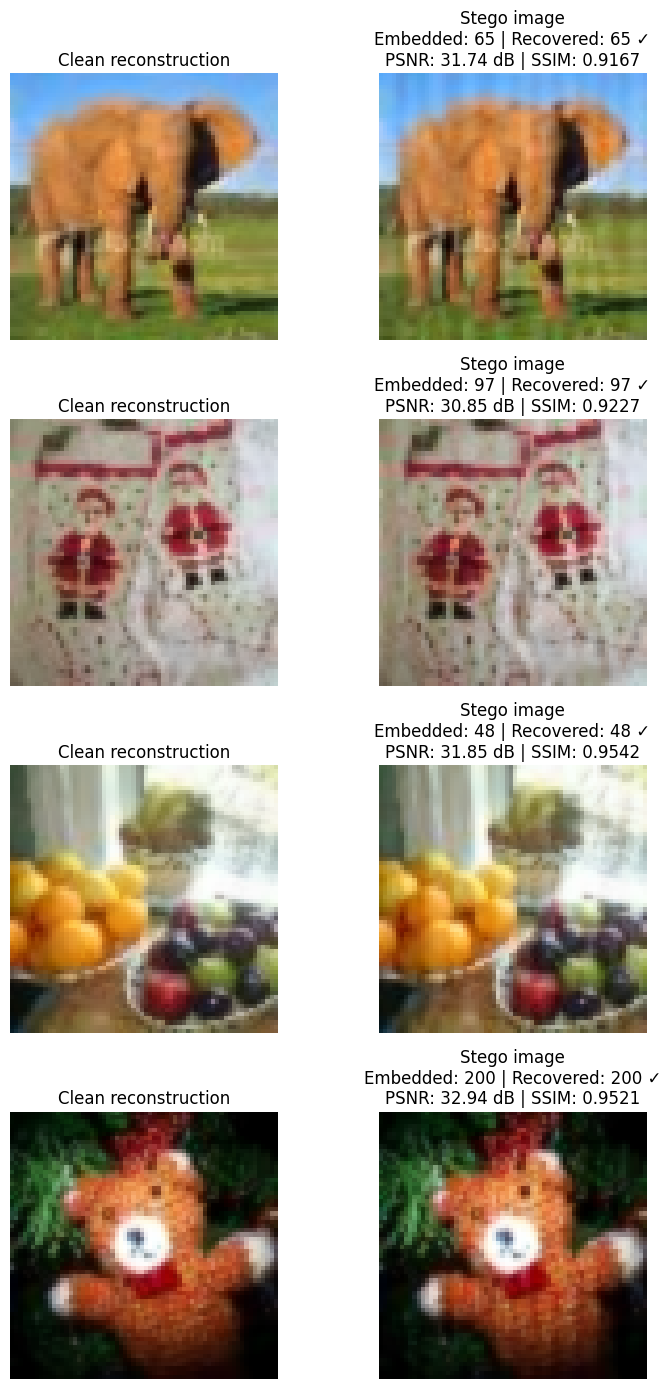

In [ ]:
import os
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchmetrics.functional.image import (
    peak_signal_noise_ratio,
    structural_similarity_index_measure
)



CHECKPOINT_PATH = (
    "/content/drive/MyDrive/"
    "TAESD_256_Message_Checkpoints/"
    "best_latent_steganography_256_classes.pth"
)

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

latent_embedder.load_state_dict(
    checkpoint["latent_embedder_state_dict"]
)

message_extractor.load_state_dict(
    checkpoint["message_extractor_state_dict"]
)

latent_embedder.eval()
message_extractor.eval()
taesd.eval()


#test settings

NUM_TEST_IMAGES = len(x_test)
NUM_CLASSES = 256
MESSAGE_BATCH_SIZE = 32

all_message_labels = torch.arange(
    NUM_CLASSES,
    dtype=torch.long,
    device=DEVICE
)



total_correct = 0
total_predictions = 0

test_losses = []

psnr_scores = []
ssim_scores = []

per_image_accuracies = []


# Four examples for visualization
example_image_indices = [
    0,
    min(1, NUM_TEST_IMAGES - 1),
    min(2, NUM_TEST_IMAGES - 1),
    min(3, NUM_TEST_IMAGES - 1)
]

example_message_labels = [
    65,   # A
    97,   # a
    48,   # 0
    200
]

visual_examples = []


#full test

with torch.no_grad():

    for image_index in range(NUM_TEST_IMAGES):

        original_64_single = x_test[
            image_index:image_index + 1
        ].to(DEVICE)

        original_512_single = upsample_512(
            original_64_single
        )

        latent_clean_single = taesd.encoder(
            original_512_single
        )

        clean_recon_512_single = taesd.decoder(
            latent_clean_single
        ).clamp(0, 1)

        clean_recon_64_single = downsample_64(
            clean_recon_512_single
        )

        image_correct = 0

        for start_index in range(
            0,
            NUM_CLASSES,
            MESSAGE_BATCH_SIZE
        ):

            end_index = min(
                start_index + MESSAGE_BATCH_SIZE,
                NUM_CLASSES
            )

            message_labels = all_message_labels[
                start_index:end_index
            ]

            current_batch_size = (
                message_labels.size(0)
            )

            latent_clean = latent_clean_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            clean_recon_64 = clean_recon_64_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            latent_embedded, _ = latent_embedder(
                latent_clean,
                message_labels
            )

            stego_512 = taesd.decoder(
                latent_embedded
            ).clamp(0, 1)

            stego_64 = downsample_64(
                stego_512
            )

            logits = message_extractor(
                stego_64
            )

            predicted_labels = logits.argmax(
                dim=1
            )

            batch_loss = F.cross_entropy(
                logits,
                message_labels
            )

            test_losses.append(
                batch_loss.item()
            )

            batch_correct = (
                predicted_labels
                == message_labels
            ).sum().item()

            image_correct += batch_correct
            total_correct += batch_correct
            total_predictions += current_batch_size

            for sample_index in range(
                current_batch_size
            ):

                sample_stego = stego_64[
                    sample_index:
                    sample_index + 1
                ]

                sample_clean = clean_recon_64[
                    sample_index:
                    sample_index + 1
                ]

                psnr_scores.append(
                    peak_signal_noise_ratio(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

                ssim_scores.append(
                    structural_similarity_index_measure(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

        image_accuracy = (
            image_correct / NUM_CLASSES
        )

        per_image_accuracies.append(
            image_accuracy
        )



# prepare visual examples


with torch.no_grad():

    for image_index, message_value in zip(
        example_image_indices,
        example_message_labels
    ):

        original_64 = x_test[
            image_index:image_index + 1
        ].to(DEVICE)

        original_512 = upsample_512(
            original_64
        )

        latent_clean = taesd.encoder(
            original_512
        )

        clean_recon_512 = taesd.decoder(
            latent_clean
        ).clamp(0, 1)

        clean_recon_64 = downsample_64(
            clean_recon_512
        )

        message_label = torch.tensor(
            [message_value],
            dtype=torch.long,
            device=DEVICE
        )

        latent_embedded, _ = latent_embedder(
            latent_clean,
            message_label
        )

        stego_512 = taesd.decoder(
            latent_embedded
        ).clamp(0, 1)

        stego_64 = downsample_64(
            stego_512
        )

        logits = message_extractor(
            stego_64
        )

        recovered_label = logits.argmax(
            dim=1
        ).item()

        example_psnr = peak_signal_noise_ratio(
            stego_64,
            clean_recon_64,
            data_range=1.0
        ).item()

        example_ssim = (
            structural_similarity_index_measure(
                stego_64,
                clean_recon_64,
                data_range=1.0
            ).item()
        )

        visual_examples.append(
            {
                "clean": clean_recon_64.squeeze(0).cpu(),
                "stego": stego_64.squeeze(0).cpu(),
                "embedded": message_value,
                "recovered": recovered_label,
                "psnr": example_psnr,
                "ssim": example_ssim
            }
        )



overall_accuracy = (
    total_correct / total_predictions
)

print("\n" + "=" * 58)
print("256-CLASS LATENT STEGANOGRAPHY RESULTS")
print("=" * 58)

print(
    f"Best training epoch     : "
    f"{checkpoint['epoch']}"
)

print(
    f"Training accuracy       : "
    f"{checkpoint['accuracy'] * 100:.2f}%"
)

print(
    f"Unseen test images      : "
    f"{NUM_TEST_IMAGES}"
)

print(
    f"Message classes         : "
    f"{NUM_CLASSES}"
)

print(
    f"Total test pairs        : "
    f"{total_predictions}"
)

print(
    f"Correct predictions     : "
    f"{total_correct}/{total_predictions}"
)

print(
    f"Overall test accuracy   : "
    f"{overall_accuracy * 100:.2f}%"
)

print(
    f"Mean test CE loss       : "
    f"{np.mean(test_losses):.4f}"
)

print("\nImage change caused by message embedding")

print(
    f"PSNR                    : "
    f"{np.mean(psnr_scores):.2f} dB"
)

print(
    f"SSIM                    : "
    f"{np.mean(ssim_scores):.4f}"
)


# show four examples

fig, axes = plt.subplots(
    4,
    2,
    figsize=(8, 14)
)

for row_index, example in enumerate(
    visual_examples
):

    clean_image = (
        example["clean"]
        .permute(1, 2, 0)
        .numpy()
    )

    stego_image = (
        example["stego"]
        .permute(1, 2, 0)
        .numpy()
    )

    axes[row_index, 0].imshow(
        clean_image
    )

    axes[row_index, 0].set_title(
        "Clean reconstruction"
    )

    axes[row_index, 0].axis(
        "off"
    )

    axes[row_index, 1].imshow(
        stego_image
    )

    is_correct = (
        example["embedded"]
        == example["recovered"]
    )

    result_symbol = (
        "✓" if is_correct else "✗"
    )

    axes[row_index, 1].set_title(
        f"Stego image\n"
        f"Embedded: {example['embedded']} | "
        f"Recovered: {example['recovered']} "
        f"{result_symbol}\n"
        f"PSNR: {example['psnr']:.2f} dB | "
        f"SSIM: {example['ssim']:.4f}"
    )

    axes[row_index, 1].axis(
        "off"
    )

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================
# SIMPLE 256-CLASS TEST
# Her test görüntüsünde 256 mesaj sınıfının tamamı denenir.
# =========================================================

import os
import numpy as np
import torch
import torch.nn.functional as F

from torchmetrics.functional.image import (
    peak_signal_noise_ratio,
    structural_similarity_index_measure
)


# =========================================================
# 1. LOAD BEST CHECKPOINT
# =========================================================

CHECKPOINT_PATH = (
    "/content/drive/MyDrive/"
    "TAESD_256_Message_Checkpoints/"
    "best_latent_steganography_256_classes.pth"
)

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint bulunamadı:\n{CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE
)

latent_embedder.load_state_dict(
    checkpoint["latent_embedder_state_dict"]
)

message_extractor.load_state_dict(
    checkpoint["message_extractor_state_dict"]
)

latent_embedder.eval()
message_extractor.eval()
taesd.eval()

print("Best checkpoint loaded")
print(f"Epoch          : {checkpoint['epoch']}")
print(
    f"Train accuracy : "
    f"{checkpoint['accuracy'] * 100:.2f}%"
)


# =========================================================
# 2. TEST SETTINGS
# =========================================================

NUM_TEST_IMAGES = len(x_test)
NUM_CLASSES = 256
MESSAGE_BATCH_SIZE = 32

all_message_labels = torch.arange(
    NUM_CLASSES,
    dtype=torch.long,
    device=DEVICE
)


# =========================================================
# 3. RESULT CONTAINERS
# =========================================================

total_correct = 0
total_predictions = 0

test_losses = []
per_image_accuracies = []

embedding_psnr_scores = []
embedding_ssim_scores = []

end_to_end_psnr_scores = []
end_to_end_ssim_scores = []


# =========================================================
# 4. TEST LOOP
# =========================================================

with torch.no_grad():

    for image_index in range(NUM_TEST_IMAGES):

        # One unseen 64x64 test image
        original_64_single = x_test[
            image_index:image_index + 1
        ].to(DEVICE)

        original_512_single = upsample_512(
            original_64_single
        )

        # Clean TAESD latent and reconstruction
        latent_clean_single = taesd.encoder(
            original_512_single
        )

        clean_recon_512_single = taesd.decoder(
            latent_clean_single
        ).clamp(0, 1)

        clean_recon_64_single = downsample_64(
            clean_recon_512_single
        )

        image_correct = 0

        # Test all 256 message classes
        for start_index in range(
            0,
            NUM_CLASSES,
            MESSAGE_BATCH_SIZE
        ):

            end_index = min(
                start_index + MESSAGE_BATCH_SIZE,
                NUM_CLASSES
            )

            message_labels = all_message_labels[
                start_index:end_index
            ]

            current_batch_size = message_labels.size(0)

            # Repeat the same image latent for each message
            latent_clean = latent_clean_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            clean_recon_64 = clean_recon_64_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            original_64 = original_64_single.repeat(
                current_batch_size,
                1,
                1,
                1
            )

            # Embed messages into latent
            latent_embedded, delta = latent_embedder(
                latent_clean,
                message_labels
            )

            # Decode stego images
            stego_512 = taesd.decoder(
                latent_embedded
            ).clamp(0, 1)

            stego_64 = downsample_64(
                stego_512
            )

            # Extract message classes
            logits = message_extractor(
                stego_64
            )

            predicted_labels = logits.argmax(
                dim=1
            )

            # Test cross-entropy loss
            batch_loss = F.cross_entropy(
                logits,
                message_labels
            )

            test_losses.append(
                batch_loss.item()
            )

            # Accuracy
            batch_correct = (
                predicted_labels
                == message_labels
            ).sum().item()

            image_correct += batch_correct
            total_correct += batch_correct
            total_predictions += current_batch_size

            # Image quality metrics
            for sample_index in range(
                current_batch_size
            ):

                sample_stego = stego_64[
                    sample_index:
                    sample_index + 1
                ]

                sample_clean = clean_recon_64[
                    sample_index:
                    sample_index + 1
                ]

                sample_original = original_64[
                    sample_index:
                    sample_index + 1
                ]

                # Additional distortion caused by embedding
                embedding_psnr_scores.append(
                    peak_signal_noise_ratio(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

                embedding_ssim_scores.append(
                    structural_similarity_index_measure(
                        sample_stego,
                        sample_clean,
                        data_range=1.0
                    ).item()
                )

                # Total distortion relative to original image
                end_to_end_psnr_scores.append(
                    peak_signal_noise_ratio(
                        sample_stego,
                        sample_original,
                        data_range=1.0
                    ).item()
                )

                end_to_end_ssim_scores.append(
                    structural_similarity_index_measure(
                        sample_stego,
                        sample_original,
                        data_range=1.0
                    ).item()
                )

        image_accuracy = (
            image_correct / NUM_CLASSES
        )

        per_image_accuracies.append(
            image_accuracy
        )

        print(
            f"Test image {image_index + 1:02d} | "
            f"{image_correct:3d}/{NUM_CLASSES} correct | "
            f"Accuracy: {image_accuracy * 100:6.2f}%"
        )


# =========================================================
# 5. FINAL SUMMARY
# =========================================================

overall_accuracy = (
    total_correct / total_predictions
)

print("\n" + "=" * 55)
print("256-CLASS STEGANOGRAPHY TEST SUMMARY")
print("=" * 55)

print(
    f"Unseen test images      : "
    f"{NUM_TEST_IMAGES}"
)

print(
    f"Message classes         : "
    f"{NUM_CLASSES}"
)

print(
    f"Total test pairs        : "
    f"{total_predictions}"
)

print(
    f"Correct predictions     : "
    f"{total_correct}/{total_predictions}"
)

print(
    f"Overall test accuracy   : "
    f"{overall_accuracy * 100:.2f}%"
)

print(
    f"Mean test CE loss       : "
    f"{np.mean(test_losses):.6f}"
)

print("\nEmbedding-only image quality")

print(
    f"PSNR                    : "
    f"{np.mean(embedding_psnr_scores):.2f} dB"
)

print(
    f"SSIM                    : "
    f"{np.mean(embedding_ssim_scores):.4f}"
)

print("\nEnd-to-end image quality")

print(
    f"PSNR                    : "
    f"{np.mean(end_to_end_psnr_scores):.2f} dB"
)

print(
    f"SSIM                    : "
    f"{np.mean(end_to_end_ssim_scores):.4f}"
)

Best checkpoint loaded
Epoch          : 75
Train accuracy : 98.54%
Test image 01 | 251/256 correct | Accuracy:  98.05%
Test image 02 | 242/256 correct | Accuracy:  94.53%
Test image 03 | 244/256 correct | Accuracy:  95.31%
Test image 04 | 242/256 correct | Accuracy:  94.53%
Test image 05 | 231/256 correct | Accuracy:  90.23%
Test image 06 | 254/256 correct | Accuracy:  99.22%
Test image 07 | 251/256 correct | Accuracy:  98.05%
Test image 08 | 251/256 correct | Accuracy:  98.05%
Test image 09 | 254/256 correct | Accuracy:  99.22%
Test image 10 | 249/256 correct | Accuracy:  97.27%
Test image 11 | 256/256 correct | Accuracy: 100.00%
Test image 12 | 251/256 correct | Accuracy:  98.05%

256-CLASS STEGANOGRAPHY TEST SUMMARY
Unseen test images      : 12
Message classes         : 256
Total test pairs        : 3072
Correct predictions     : 2976/3072
Overall test accuracy   : 96.88%
Mean test CE loss       : 0.171879

Embedding-only image quality
PSNR                    : 31.91 dB
SSIM        